In [1]:
!pip install matplotlib
!pip install seaborn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: C:\Program Files\Python312\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: C:\Program Files\Python312\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv("DeSense_Feature_Engineered_Dataset.csv")

Rides by city

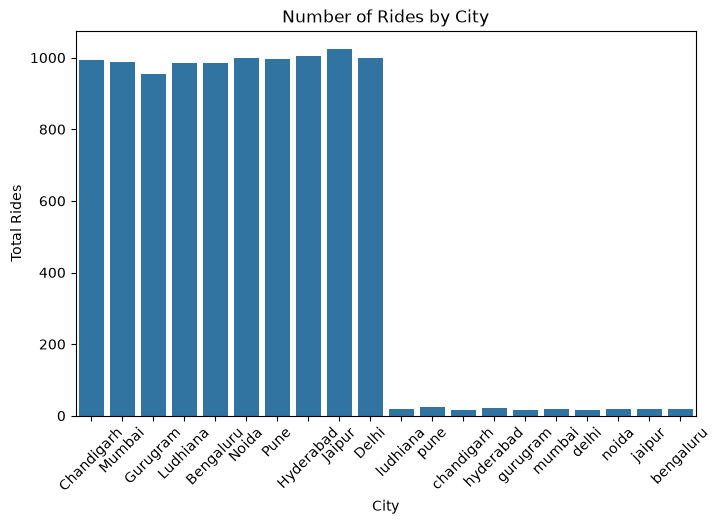

In [6]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='City')

plt.title("Number of Rides by City")
plt.xlabel("City")
plt.ylabel("Total Rides")

plt.xticks(rotation=45)
plt.show()

Rides by each vehicle

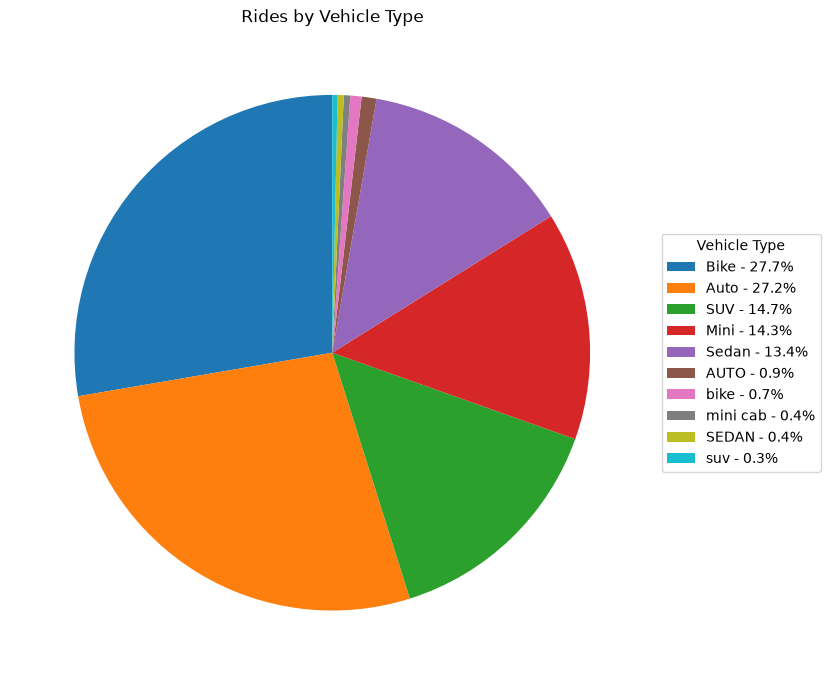

In [11]:
vehicle_counts = df['Vehicle_Type'].value_counts()

plt.figure(figsize=(8, 7))

plt.pie(
    vehicle_counts,
    startangle=90,
    labels=None
)

legend_labels = [
    f"{name} - {value / vehicle_counts.sum() * 100:.1f}%"
    for name, value in vehicle_counts.items()
]

plt.legend(
    legend_labels,
    title="Vehicle Type",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("Rides by Vehicle Type")
plt.tight_layout()
plt.show()

Monthly Ride Trends

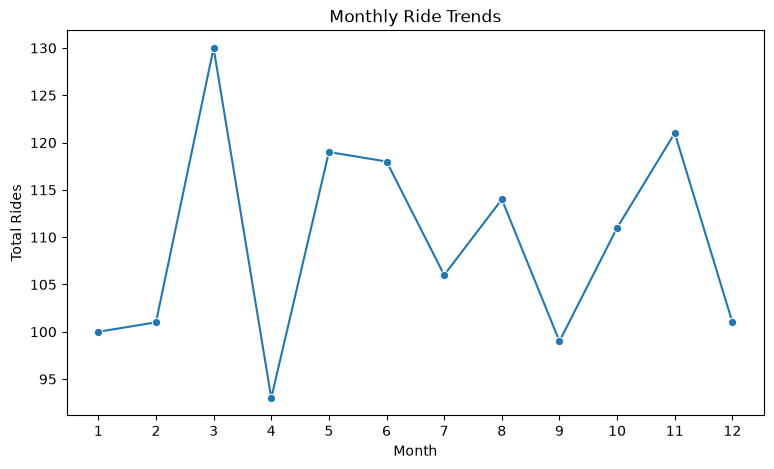

In [12]:
monthly_rides = df['Ride_Month'].value_counts().sort_index()

plt.figure(figsize=(9,5))

sns.lineplot(
    x=monthly_rides.index,
    y=monthly_rides.values,
    marker='o'
)

plt.title("Monthly Ride Trends")
plt.xlabel("Month")
plt.ylabel("Total Rides")
plt.xticks(range(1,13))

plt.show()

Fare Amount Distribution

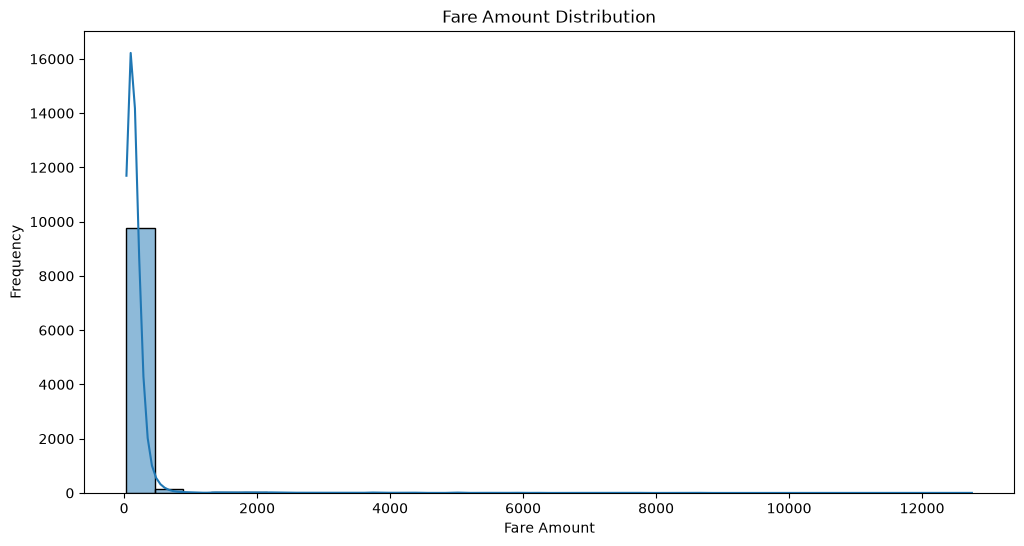

In [17]:
plt.figure(figsize=(12,6))

sns.histplot(
    data=df,
    x='Fare_Amount',
    bins=30,
    kde=True
)

plt.title("Fare Amount Distribution")
plt.xlabel("Fare Amount")
plt.ylabel("Frequency")

plt.show()

Fare Amount Outlier Detection

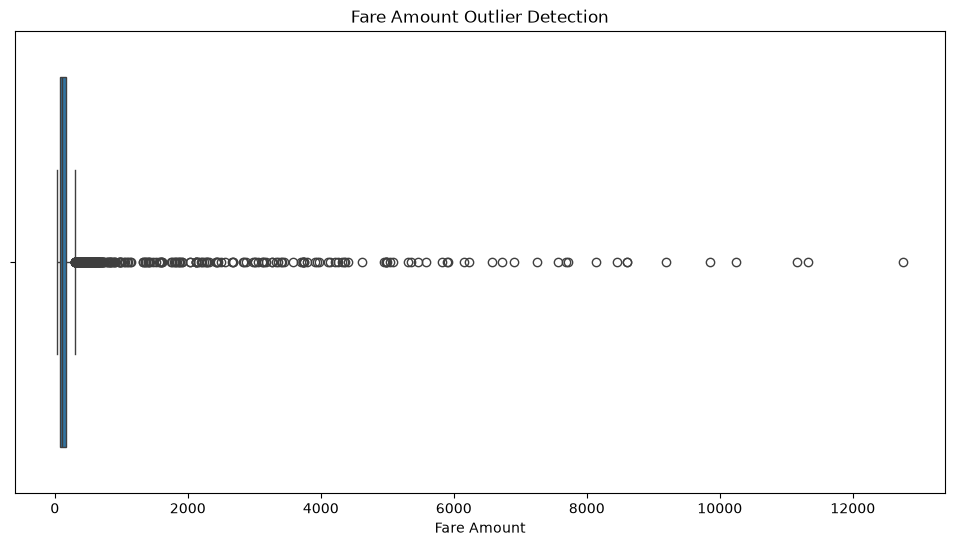

In [16]:
plt.figure(figsize=(12,6))

sns.boxplot(data=df, x='Fare_Amount')

plt.title("Fare Amount Outlier Detection")
plt.xlabel("Fare Amount")

plt.show()

Ride Status Distribution

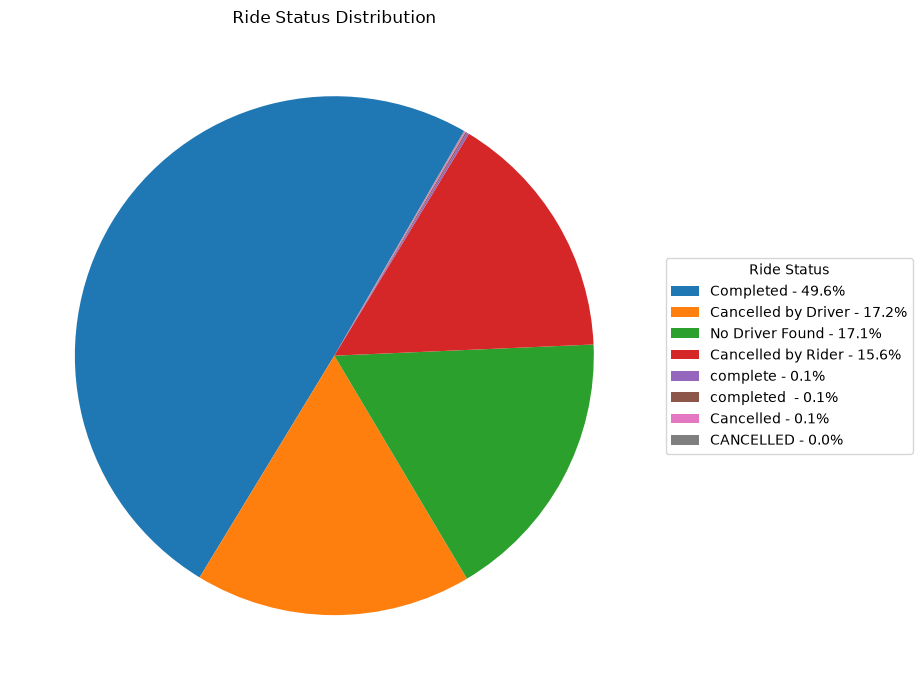

In [20]:
status_counts = df['Ride_Status'].value_counts()

plt.figure(figsize=(9, 7))

plt.pie(
    status_counts,
    labels=None,
    startangle=60
)

legend_labels = [
    f"{name} - {value / status_counts.sum() * 100:.1f}%"
    for name, value in status_counts.items()
]

plt.legend(
    legend_labels,
    title="Ride Status",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("Ride Status Distribution")
plt.tight_layout()
plt.show()

Average Ride Duration by City

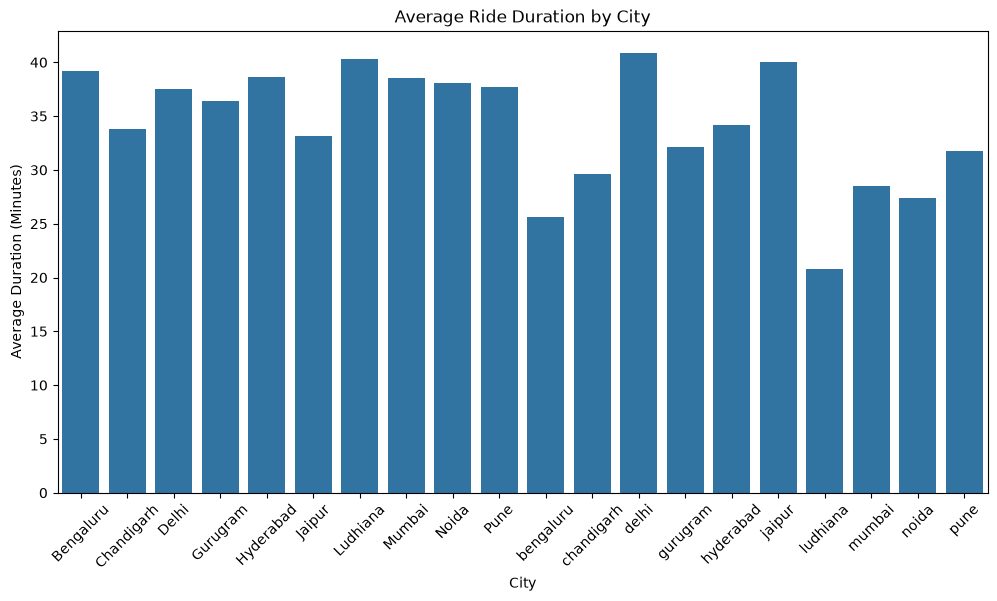

In [21]:
city_duration = df.groupby('City')['Ride_Duration_Minutes'].mean()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=city_duration.index,
    y=city_duration.values
)

plt.title("Average Ride Duration by City")
plt.xlabel("City")
plt.ylabel("Average Duration (Minutes)")
plt.xticks(rotation=45)

plt.show()

Average Fare per KM by Vehicle Type

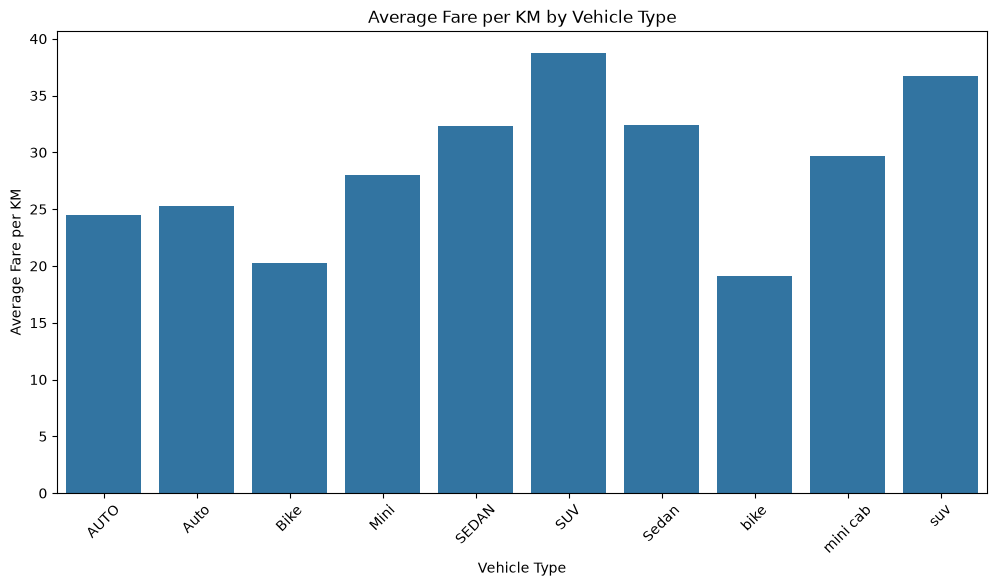

Surge Multiplier vs Fare Amount

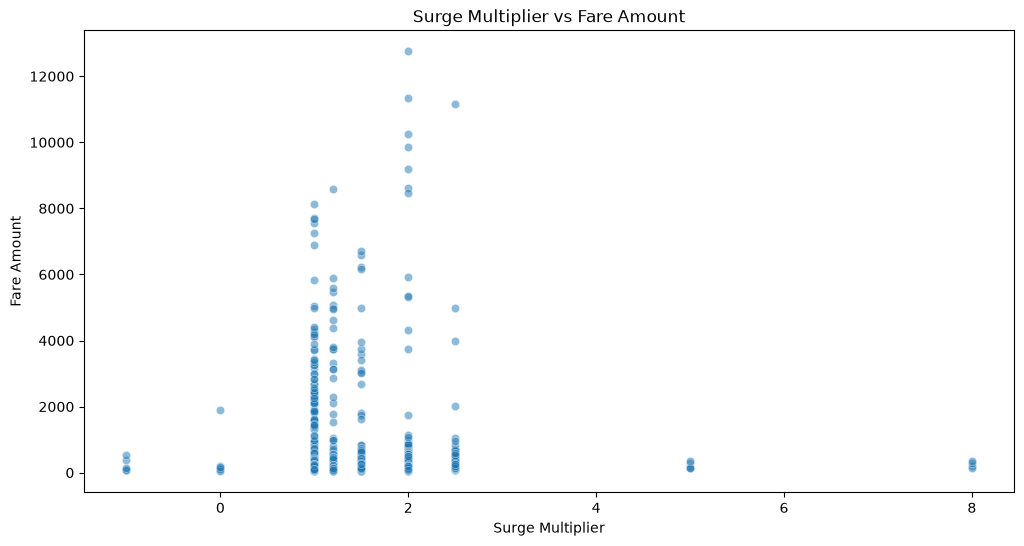

In [26]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x='Surge_Multiplier',
    y='Fare_Amount',
    alpha=0.5
)

plt.title("Surge Multiplier vs Fare Amount")
plt.xlabel("Surge Multiplier")
plt.ylabel("Fare Amount")

plt.show()

Ride Duration Distribution by City

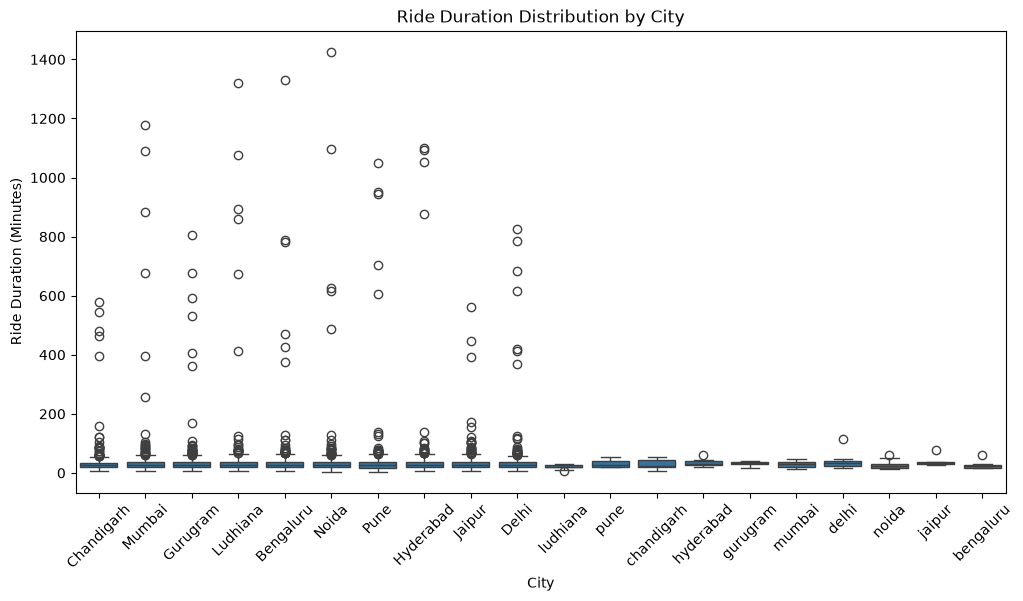

In [27]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='City',
    y='Ride_Duration_Minutes'
)

plt.title("Ride Duration Distribution by City")
plt.xlabel("City")
plt.ylabel("Ride Duration (Minutes)")
plt.xticks(rotation=45)

plt.show()

Ride Status Count

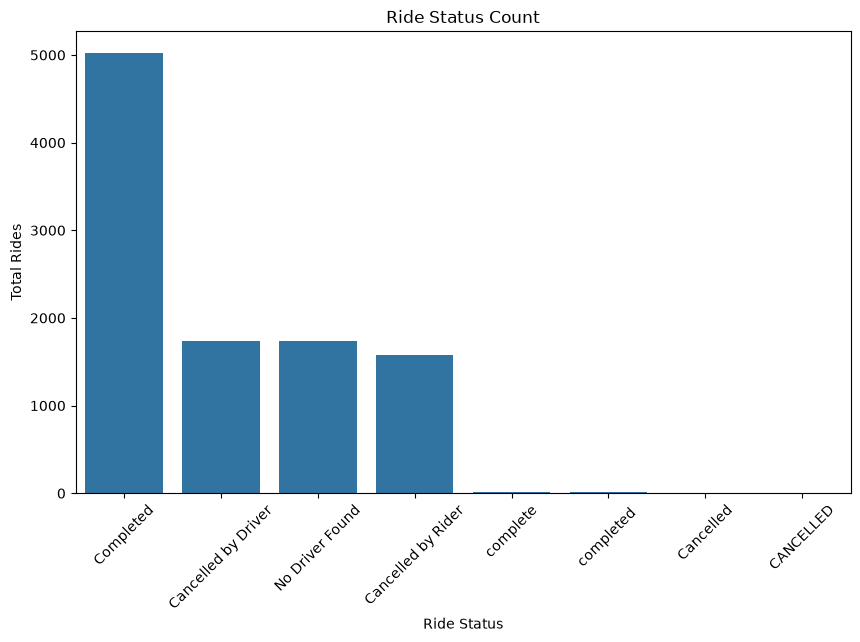

In [28]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='Ride_Status',
    order=df['Ride_Status'].value_counts().index
)

plt.title("Ride Status Count")
plt.xlabel("Ride Status")
plt.ylabel("Total Rides")
plt.xticks(rotation=45)

plt.show()

Correlation Heatmap

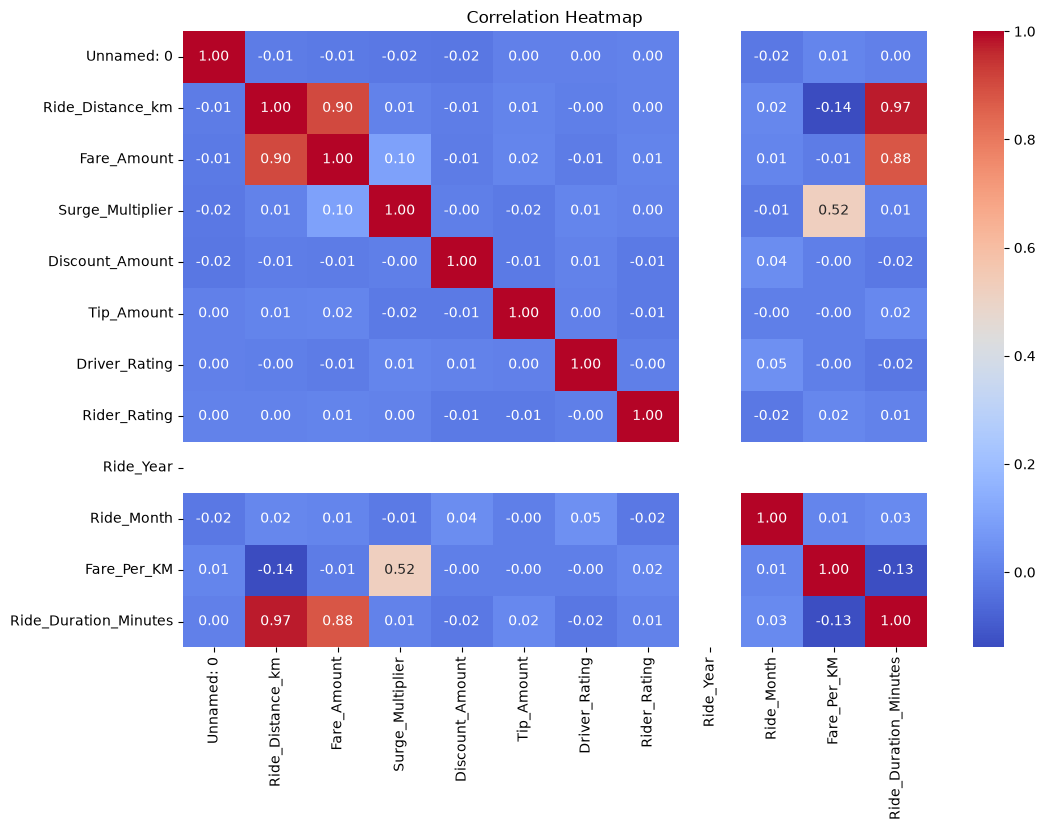

In [29]:
numerical_df = df.select_dtypes(include='number')

plt.figure(figsize=(12, 8))

sns.heatmap(
    numerical_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

# Final Business Insights

1. The city with the highest number of rides is Jaipur.

2. The most popular vehicle type is Bike.

3. The vehicle type with the highest average fare per KM is SUV.

4. The city with the highest average ride duration is Delhi.

5. Surge multiplier has a week relationship with fare amount.

6. The dataset contains potential outliers in Fare_Amount and Ride_Duration_Minutes.

7. The most common ride status is Completed.

8. Numerical features such as Ride_Distance_km, Fare_Amount, Surge_Multiplier and Ride_Duration_Minutes may be useful for machine learning.


# Final Conclusion

1. The DeSense dataset contains ride-sharing information from different cities and vehicle types.

2. Data visualization helped us understand ride patterns and business performance.

3. Different vehicle types showed different ride counts and average fares.

4. City-wise analysis helped identify differences in ride duration.

5. Surge multiplier helps us understand changes in ride fares during high demand.

6. The dataset contains potential outliers in fare amount and ride duration.

7. Ride status analysis helps us understand completed and non-completed rides.

8. Correlation analysis helps identify relationships between numerical features.

9. Features such as ride distance, surge multiplier and ride duration may be useful for machine learning.

10. Overall, visualization helps us understand the dataset before building machine learning models.

Vehicle Type vs Ride Count and Fare

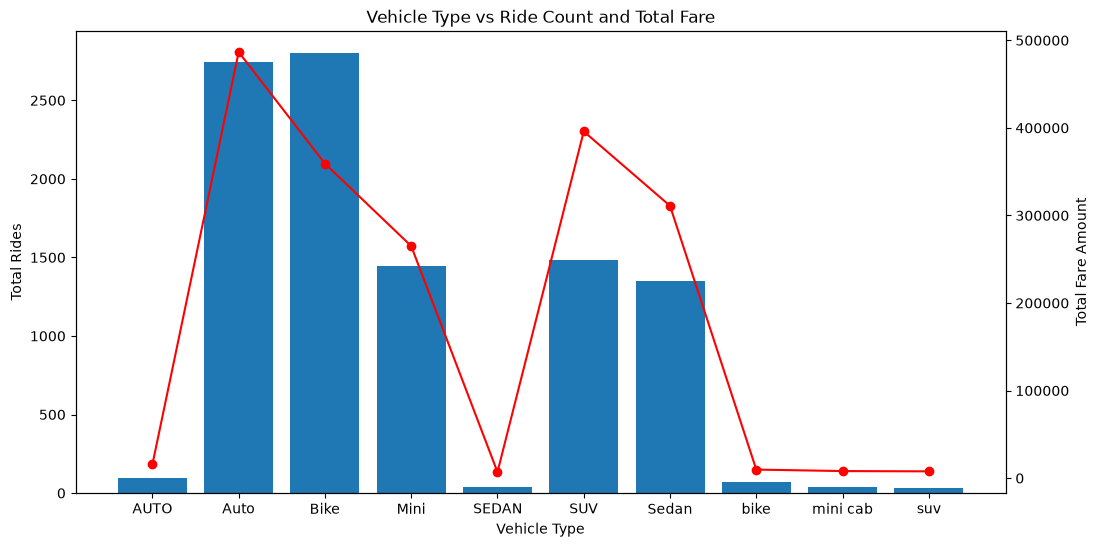

In [30]:
vehicle_data = df.groupby('Vehicle_Type').agg({
    'Ride_ID': 'count',
    'Fare_Amount': 'sum'
}).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(
    vehicle_data['Vehicle_Type'],
    vehicle_data['Ride_ID']
)

ax1.set_xlabel("Vehicle Type")
ax1.set_ylabel("Total Rides")
ax1.set_title("Vehicle Type vs Ride Count and Total Fare")

ax2 = ax1.twinx()

ax2.plot(
    vehicle_data['Vehicle_Type'],
    vehicle_data['Fare_Amount'],
    marker='o',
    color='red'
)

ax2.set_ylabel("Total Fare Amount")

plt.xticks(rotation=45)
plt.show()

# Business Recommendation

The business should focus on vehicle types that generate a good number of rides and higher total fare. It should also analyse vehicle demand and improve services for less popular vehicle types.